# GlucoScope: reproducible investigation

Author: Mushtahir Kabir & team. Run cells in order after `python src/train.py`. Educational survey-label classification, not diagnosis. See `docs/research-report.md` for the protocol and limitations.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/'src'))
from download import download
df = pd.read_csv(download())
audit = json.loads((ROOT/'dist/assets/audit.json').read_text())
results = json.loads((ROOT/'dist/assets/results.json').read_text())
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print('Shape:', df.shape)
print(df.dtypes.to_string())

Dataset SHA-256: 9f71fda9d4ae5f4878c99b9233b6a16accfa9a17c194116a6b78100540934964
Shape: (253680, 23)
ID                      int64
Diabetes_binary         int64
HighBP                  int64
HighChol                int64
CholCheck               int64
BMI                     int64
Smoker                  int64
Stroke                  int64
HeartDiseaseorAttack    int64
PhysActivity            int64
Fruits                  int64
Veggies                 int64
HvyAlcoholConsump       int64
AnyHealthcare           int64
NoDocbcCost             int64
GenHlth                 int64
MentHlth                int64
PhysHlth                int64
DiffWalk                int64
Sex                     int64
Age                     int64
Education               int64
Income                  int64


## Data quality
IDs and targets are excluded from inputs. Retain identical profiles but keep each profile within one split.

In [2]:
X = df.drop(columns=['ID','Diabetes_binary'])
print('Missing:', int(df.isna().sum().sum()))
print('Repeated feature rows:', int(X.duplicated().sum()))
print('Target counts:', df.Diabetes_binary.value_counts().to_dict())
print(pd.DataFrame(audit['splits']).T.to_string())

Missing: 0
Repeated feature rows: 25772
Target counts: {0: 218334, 1: 35346}
                    n  positive  prevalence
train        152208.0   21209.0    0.139342
calibration   25368.0    3534.0    0.139309
validation    25368.0    3534.0    0.139309
test          50736.0    7069.0    0.139329


## Class imbalance and descriptive feature distribution
These plots describe the full sample. They are not population-weighted prevalence estimates.

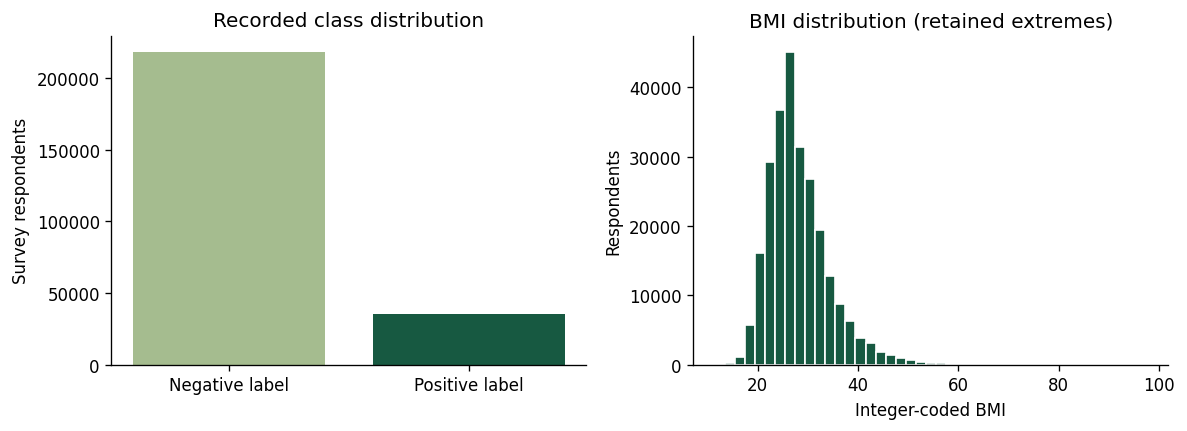

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
c = df.Diabetes_binary.value_counts().sort_index()
axes[0].bar(['Negative label','Positive label'], c.values, color=['#a5bc8f','#175941'])
axes[0].set_title('Recorded class distribution')
axes[0].set_ylabel('Survey respondents')
axes[1].hist(df.BMI, bins=np.arange(11.5,99.5,2),color='#175941',edgecolor='white')
axes[1].set_title('BMI distribution (retained extremes)')
axes[1].set_xlabel('Integer-coded BMI')
axes[1].set_ylabel('Respondents')
fig.tight_layout()
plt.show()

## Training and model selection
Training CV chooses hyperparameters; calibration fits sigmoid mappings; validation selects the full-model winner and F1 thresholds. Test results do not change those choices.

In [4]:
summary = pd.DataFrame([{'model':m['name'], 'CV AP':m['cv_ap'], 'validation AP':m['validation']['ap'], **{k:v for k,v in m['test'].items() if k!='confusion'}} for m in results['models']])
print(summary.round(4).to_string(index=False))
print('Selected before test:', results['winner'])

              model  CV AP  validation AP  accuracy  precision  recall     f1     ap    auc  brier  threshold
Logistic regression 0.4031         0.4046    0.7885     0.3564  0.6432 0.4587 0.4081 0.8230 0.0989     0.1936
      Decision tree 0.4014         0.4054    0.7792     0.3475  0.6663 0.4567 0.4126 0.8180 0.1001     0.1443
      Random forest 0.4257         0.4232    0.8024     0.3742  0.6220 0.4673 0.4308 0.8274 0.0985     0.1723
  Gradient boosting 0.4267         0.4220    0.7996     0.3718  0.6356 0.4692 0.4321 0.8287 0.0971     0.2047
Short-form logistic 0.3945         0.3961    0.7836     0.3500  0.6455 0.4539 0.4018 0.8186 0.0995     0.1911
Selected before test: Random forest


## Precision–recall and ROC curves
Curves below use sampled coordinates exported from the full test predictions. The metric values themselves use all predictions.

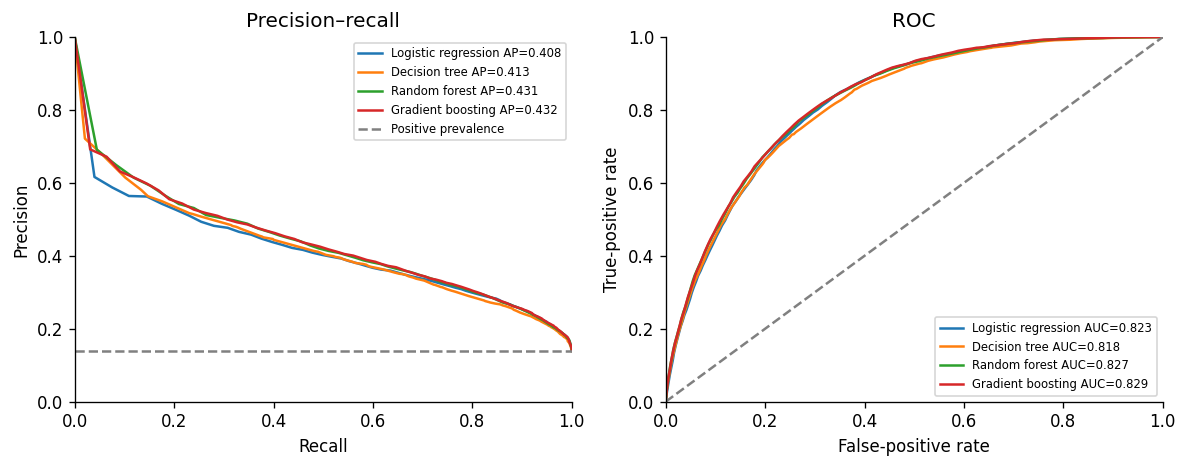

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for m in results['models'][:4]:
 p=np.array(m['pr_curve']); q=np.array(m['roc_curve'])
 axes[0].plot(p[:,0],p[:,1],label=f"{m['name']} AP={m['test']['ap']:.3f}")
 axes[1].plot(q[:,0],q[:,1],label=f"{m['name']} AUC={m['test']['auc']:.3f}")
axes[0].axhline(results['test_positive']/results['test_n'],color='gray',ls='--',label='Positive prevalence')
axes[1].plot([0,1],[0,1],color='gray',ls='--')
axes[0].set(xlabel='Recall',ylabel='Precision',title='Precision–recall',xlim=(0,1),ylim=(0,1))
axes[1].set(xlabel='False-positive rate',ylabel='True-positive rate',title='ROC',xlim=(0,1),ylim=(0,1))
for ax in axes: ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Calibration and errors
Calibration quality is separate from ranking. The classification threshold is chosen on validation data.

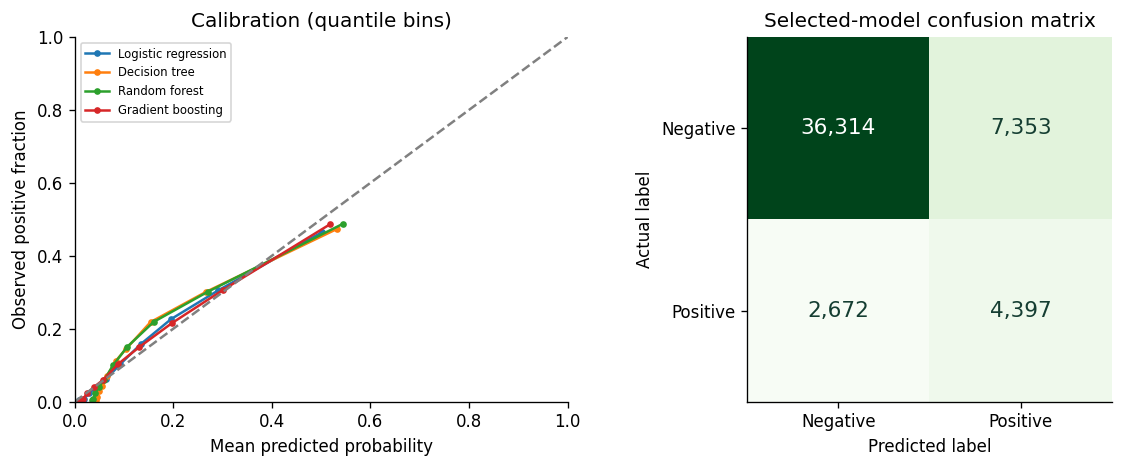

In [6]:
winner=next(m for m in results['models'] if m['name']==results['winner'])
fig, axes=plt.subplots(1,2,figsize=(10,4))
for m in results['models'][:4]:
 c=np.array(m['calibration_curve']); axes[0].plot(c[:,0],c[:,1],marker='o',ms=3,label=m['name'])
axes[0].plot([0,1],[0,1],ls='--',color='gray')
axes[0].set(xlabel='Mean predicted probability',ylabel='Observed positive fraction',title='Calibration (quantile bins)',xlim=(0,1),ylim=(0,1))
axes[0].legend(fontsize=7)
cm=np.array(winner['test']['confusion']); axes[1].imshow(cm,cmap='Greens')
for i in range(2):
 for j in range(2): axes[1].text(j,i,f'{cm[i,j]:,}',ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else '#153e32',fontsize=13)
axes[1].set(xticks=[0,1],yticks=[0,1],xticklabels=['Negative','Positive'],yticklabels=['Negative','Positive'],xlabel='Predicted label',ylabel='Actual label',title='Selected-model confusion matrix')
fig.tight_layout()
plt.show()

## Subgroup audit and shortened inputs
Descriptive results do not certify fairness. Short-form retention compares the same algorithm at different input lengths.

In [7]:
print(pd.DataFrame(winner['subgroups'])[['group','label','n','positive','recall','fpr','ap','brier']].round(4).to_string(index=False))
full=next(m for m in results['models'] if m['name']=='Logistic regression')
short=next(m for m in results['models'] if m['name']=='Short-form logistic')
print('Input reduction:',1-8/21)
print('Average precision retained:',short['test']['ap']/full['test']['ap'])
print('Bootstrap:',results['uncertainty'])

group label     n  positive  recall    fpr     ap  brier
  Sex     0 28359      3701  0.6409 0.1606 0.4383 0.0915
  Sex     1 22377      3368  0.6012 0.1785 0.4228 0.1072
  Age 18–44 10905       422  0.3318 0.0323 0.2430 0.0335
  Age 45–64 21939      2995  0.6190 0.1598 0.4320 0.0965
  Age   65+ 17892      3652  0.6580 0.2800 0.4479 0.1404
Input reduction: 0.6190476190476191
Average precision retained: 0.984494153405365
Bootstrap: {'method': '200 feature-profile cluster bootstrap replicates; percentile 95% intervals; fixed fitted models', 'winner_recall_ci': [0.6112683445706539, 0.6320109968702674], 'ap_difference_vs_logistic_ci': [0.01610413780054489, 0.02852416852508818]}


## Conclusion
The final report explains the selected model, modest gains, false alarms, missed positive labels, subgroup variation, and limitations. No clinical or causal benefit is established. Next work should use a new independent evaluation cohort rather than tuning repeatedly against this test set.